# 02 Basaltic glass (EPMA, session 20/12/2016)

Same steps as `01_olivine`. Differences: four standards instead of one, so each oxide is corrected with the standard it was calibrated on, and there is no Fo/Fa file (step 7 does not apply).

In [1]:
# --- config ---
from pathlib import Path
import sys, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore", message="Unknown extension")      # harmless openpyxl warning on Standards.xlsx
sys.path.insert(0, "src")
from geohelpers import read_jeol, read_dl, read_cal, read_ref, mean_2sd

DATA, OUT, FIG = Path("data"), Path("outputs"), Path("figures/glass")
OUT.mkdir(exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
REF_ROWS = {"Std VGA99": "VGA99", "Std VG2": "VG-2", "Std Scapolite": "Scap", "Std KE3": "KE3"}   # xlsx row: session name
CAL_NAME = {"VGA99-15KV": "VGA99", "Scapolite_bgls": "Scap", "KE3": "KE3"}                     # std-cnd name: session name
OX = ["SiO2", "TiO2", "Al2O3", "FeO", "MnO", "MgO", "CaO", "Na2O", "K2O", "P2O5", "SO3", "Cl", "F"]
PER_BRACKET = 2                                    # each standard was measured twice at each standard bracket
pd.set_option("display.width", 200, "display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight", "font.size": 9})

## Steps 1 and 2. One table

There is no ratios file for the glass, so step 1 is the `_oxide` file alone; Comment first, then the oxides. The last number in a Comment is the spot (9 per sample). `UnknA-Flow1-1` was measured twice under the same name (No. 71 to 79 and 89 to 97): the second run is kept as a separate set, `UnknA-Flow1-1 (run 2)`, and compared with the first before anything is averaged.

In [2]:
gl = read_jeol(DATA / "bgls_20122016_oxide.txt")
gl["Sample"] = gl.Comment.str.rstrip("_").str.rsplit("_", n=1).str[0]
gl.loc[gl.Sample.eq("UnknA-Flow1-1") & gl["No."].between(89, 97), "Sample"] = "UnknA-Flow1-1 (run 2)"
gl = gl[["No.", "Comment", "Sample"] + OX + ["Total"]]
is_std = gl.Sample.isin(REF_ROWS.values())

print(gl[is_std].groupby("Sample")["No."].apply(list).to_string())
print(gl[~is_std].groupby("Sample").size().to_string())

Sample
KE3      [5, 6, 58, 59, 102, 103]
Scap     [7, 8, 60, 61, 104, 105]
VG-2     [3, 4, 56, 57, 100, 101]
VGA99      [1, 2, 54, 55, 98, 99]
Sample
1982-CS2-L3A             9
1982-CS2-L5B             9
UnknA-BatokeCS1-3        9
UnknA-C21                9
UnknA-C22-PS1-L2         9
UnknA-C22-PS1-L3         9
UnknA-Flow1-1            9
UnknA-Flow1-1 (run 2)    9
UnknA-Flow1-2            9


## Step 3. Plot the standards and remove obvious outliers by eye

Each oxide is plotted as measured / reference value for every standard that has a reference value, so all standards share one axis and 1 means "equal to the reference". The mean of these points per standard is that standard's correction factor.

**Reference values:** `Standards.xlsx` (S converted to SO₃ × 2.4972), replaced by the more precise values in `bgls_20122016_std-cnd.txt` for each oxide's calibration standard (VGA99: nine oxides; Scapolite: SO₃, Cl; KE3: F).

**Removed:** KE3 No. 6, Na₂O: 2.36 wt% against 6.21 to 6.44 for the other KE3 analyses. Shown for completeness; KE3 has no Na₂O reference and is used only for F, so it changes no correction.

**Kept:** in the last bracket VGA99 (No. 98, 99) and VG-2 (No. 100) read 1 to 4 % lower in SiO₂ and Al₂O₃ than in the first two brackets. This is shared by the bracket, i.e. it is the state of the instrument at the end of the session, not a bad analysis.

          SiO2    TiO2    Al2O3      FeO   MnO    MgO      CaO    Na2O     K2O    P2O5     SO3      Cl      F
VGA99  50.9342  4.0534  12.4899  13.3022  0.15  5.074   9.3047  2.6555  0.8191  0.3896  0.0425  0.0271    NaN
VG-2   50.8100  1.8500  14.0600  11.8400  0.22  6.710  11.1200  2.6200  0.1900  0.2000  0.3571  0.0329  0.032
Scap   49.7800     NaN  25.0500   0.1700   NaN    NaN  13.5800  5.2000  0.9400     NaN  1.3235  1.4300  0.016
KE3        NaN     NaN      NaN      NaN   NaN    NaN      NaN     NaN     NaN     NaN  0.0300  0.3900  0.470


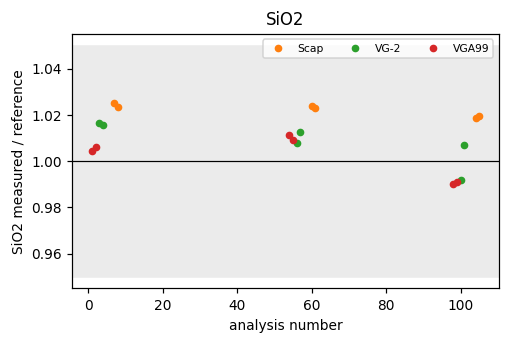

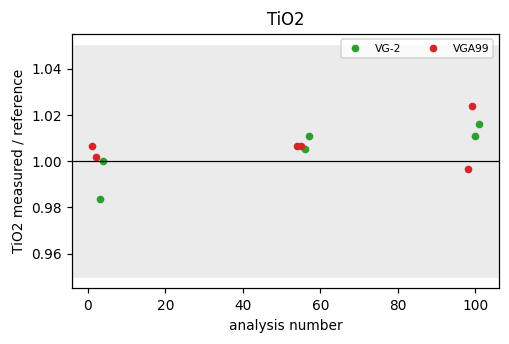

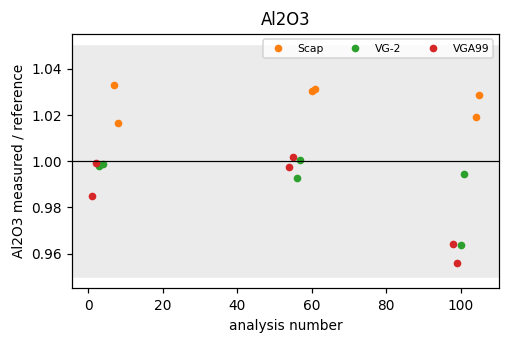

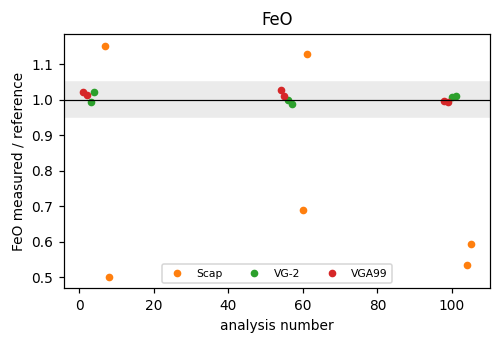

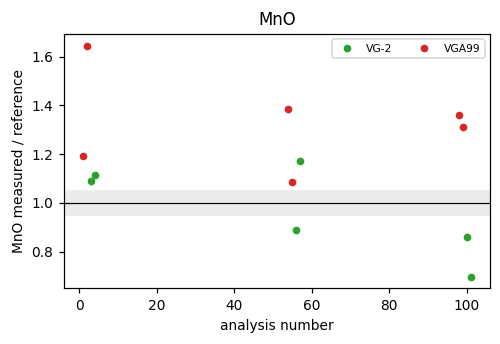

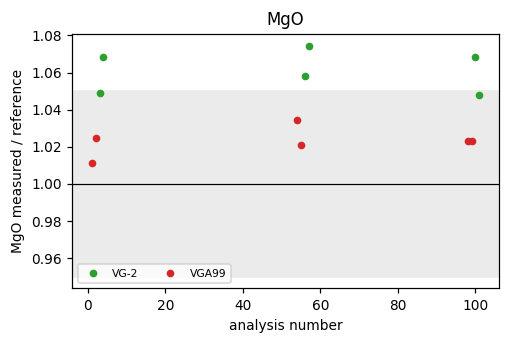

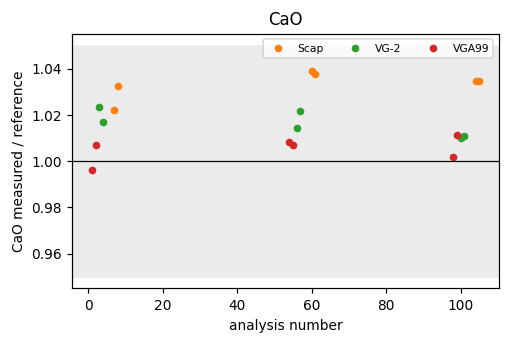

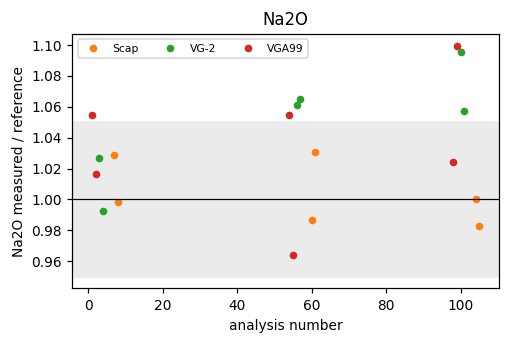

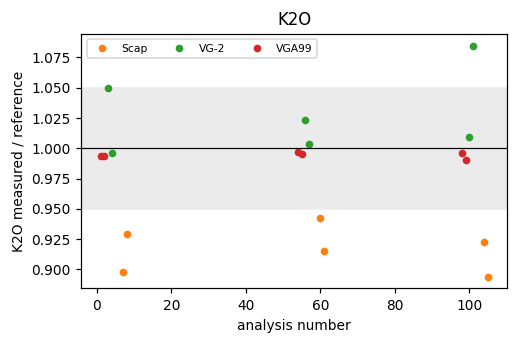

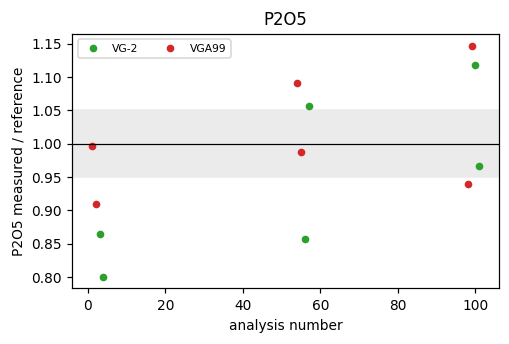

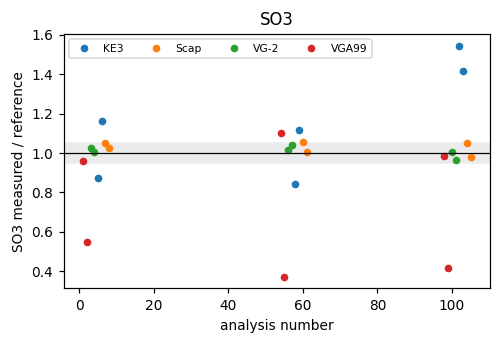

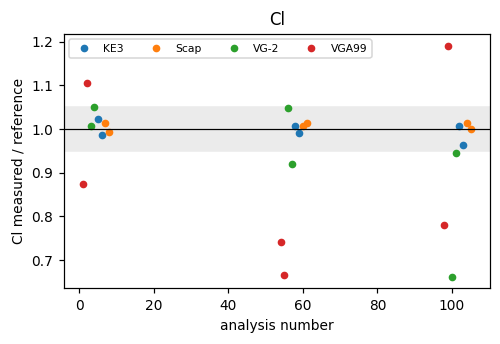

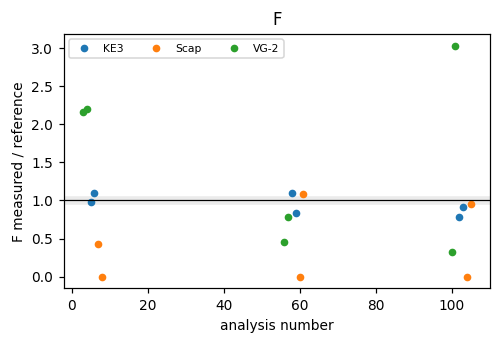

In [3]:
ref = read_ref(DATA / "Standards.xlsx", REF_ROWS)[OX]
src = pd.DataFrame("Standards.xlsx", index=ref.index, columns=OX)
cal = read_cal(DATA / "bgls_20122016_std-cnd.txt")
cal["std"] = cal.standard.map(CAL_NAME)
for _, r in cal.dropna(subset=["std"]).iterrows():
    ref.loc[r["std"], r.oxide], src.loc[r["std"], r.oxide] = r.value, "std-cnd"
print(ref.round(4).to_string())

std = gl[is_std].set_index("No.")
DROP = {("KE3", "Na2O"): [6]}
clean = std[["Sample"] + OX].copy()
for (s, el), nos in DROP.items():
    clean.loc[nos, el] = np.nan

def plot_std(el, fname=None):
    fig, ax = plt.subplots(figsize=(5, 3))
    for i, (s, d) in enumerate(std.groupby("Sample")):
        if pd.isna(ref.at[s, el]): continue
        keep = clean.loc[d.index, el].notna()
        r = d[el] / ref.at[s, el]
        ax.plot(d.index[keep], r[keep], "o", ms=4, color=f"C{i}", label=s)
        ax.plot(d.index[~keep], r[~keep], "x", ms=8, mew=2, color=f"C{i}")
    ax.axhline(1, color="k", lw=0.8); ax.axhspan(0.95, 1.05, color="0.92", zorder=0)
    ax.set(xlabel="analysis number", ylabel=f"{el} measured / reference", title=el)
    ax.legend(fontsize=7, ncol=4)
    if fname: fig.savefig(fname)
    plt.show()

for el in OX:
    plot_std(el, FIG / f"std_{el}.png")

## Step 4. Mean, SD and correction factor; correct every analysis

For each standard and oxide: n, mean, SD and CF = mean / reference. Each oxide is then corrected with the CF of **its calibration standard** (from `_std-cnd`), because that is the standard the instrument assumed to be right. MnO was calibrated on rhodonite, which was not measured in this session. Of the two basaltic standards, VG-2 agrees with that calibration within 3 %, while VGA99 reads 33 % above its reference value; correcting with VGA99 would lower every sample's MnO by a quarter on the evidence of one standard that disagrees with both the calibration and VG-2, so MnO is corrected with VG-2. Every analysis is divided by its oxide's CF; the total is recomputed.

In [4]:
long = clean.melt(id_vars="Sample", value_vars=OX, var_name="oxide").dropna()
st = long.groupby(["Sample", "oxide"])["value"].agg(n="count", mean="mean", SD="std")
st["reference"] = [ref.at[s, o] for s, o in st.index]
st["source"] = [src.at[s, o] for s, o in st.index]
st["CF"] = st["mean"] / st["reference"]

CF_STD = cal.set_index("oxide")["std"].reindex(OX)
CF_STD["MnO"] = "VG-2"
cf = st.loc[list(zip(CF_STD.values, CF_STD.index))].reset_index().set_index("oxide").rename(columns={"Sample": "standard"})
print(cf.round(4).to_string())

corr = gl.copy()
corr[OX] = gl[OX] / cf["CF"]
corr["Total"] = corr[OX].sum(axis=1)

with pd.ExcelWriter(OUT / "glass_step4_standards.xlsx") as xw:
    std.reset_index().to_excel(xw, sheet_name="standards raw", index=False)
    st.to_excel(xw, sheet_name="standard statistics")
    cf.to_excel(xw, sheet_name="correction factors")
    gl.to_excel(xw, sheet_name="all raw", index=False)
    corr.to_excel(xw, sheet_name="all corrected", index=False)

      standard  n     mean      SD  reference          source      CF
oxide                                                                
SiO2     VGA99  6  51.0350  0.4648    50.9342         std-cnd  1.0020
TiO2     VGA99  6   4.0817  0.0371     4.0534         std-cnd  1.0070
Al2O3    VGA99  6  12.2883  0.2443    12.4899         std-cnd  0.9839
FeO      VGA99  6  13.4317  0.1829    13.3022         std-cnd  1.0097
MnO       VG-2  6   0.2135  0.0404     0.2200  Standards.xlsx  0.9705
MgO      VGA99  6   5.1900  0.0385     5.0740         std-cnd  1.0229
CaO      VGA99  6   9.3533  0.0501     9.3047         std-cnd  1.0052
Na2O     VGA99  6   2.7500  0.1212     2.6555         std-cnd  1.0356
K2O      VGA99  6   0.8145  0.0020     0.8191         std-cnd  0.9944
P2O5     VGA99  6   0.3942  0.0355     0.3896         std-cnd  1.0118
SO3       Scap  6   1.3603  0.0410     1.3235         std-cnd  1.0278
Cl        Scap  6   1.4400  0.0126     1.4300         std-cnd  1.0070
F          KE3  6   

## Step 5. Flag correction factors outside ±5 %

Shown for every standard with a reference value, not only the calibration standards: a standard far from 1 for an oxide it does not calibrate is a matrix or reference-value problem, not a reason to correct.

calibration CFs outside ±5 %:
      standard    mean  reference      CF
oxide                                    
F          KE3  0.4462       0.47  0.9493

all standards outside ±5 %:
              n    mean  reference      CF
Sample oxide                              
KE3    F      6  0.4462     0.4700  0.9493
       SO3    6  0.0347     0.0300  1.1591
Scap   F      6  0.0066     0.0160  0.4104
       FeO    6  0.1302     0.1700  0.7662
       K2O    6  0.8618     0.9400  0.9168
VG-2   Cl     6  0.0309     0.0329  0.9389
       F      6  0.0477     0.0320  1.4911
       MgO    6  7.1200     6.7100  1.0611
       P2O5   6  0.1888     0.2000  0.9438
VGA99  Cl     6  0.0242     0.0271  0.8932
       MnO    6  0.1994     0.1500  1.3296
       SO3    6  0.0310     0.0425  0.7302


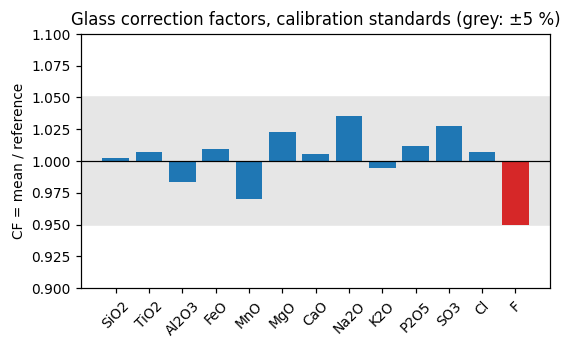

In [5]:
st["flag"] = (st.CF - 1).abs() > 0.05
cf["flag"] = (cf.CF - 1).abs() > 0.05
print("calibration CFs outside ±5 %:"); print(cf.loc[cf.flag, ["standard", "mean", "reference", "CF"]].round(4).to_string())
print("\nall standards outside ±5 %:"); print(st.loc[st.flag, ["n", "mean", "reference", "CF"]].round(4).to_string())

fig, ax = plt.subplots(figsize=(5.5, 3))
ax.bar(cf.index, cf.CF - 1, bottom=1, color=np.where(cf.flag, "C3", "C0"))
ax.set_ylim(min(0.9, cf.CF.min() - 0.02), max(1.1, cf.CF.max() + 0.02))
ax.axhspan(0.95, 1.05, color="0.9", zorder=0); ax.axhline(1, color="k", lw=0.8)
ax.set(ylabel="CF = mean / reference", title="Glass correction factors, calibration standards (grey: ±5 %)")
ax.tick_params(axis="x", rotation=45)
fig.savefig(FIG / "cf.png"); plt.show()

## Step 6. Accuracy from a held-out standard, and from VG-2

After correction the calibration standards equal their references by construction. Two independent tests instead:
1. **Hold-out:** CF from the first analysis of each bracket (n = 3), applied to the second (n = 3).
2. **Independent standard:** VG-2 is not a calibration standard, so its corrected mean is a real accuracy test for every oxide except MnO, where VGA99 takes that role.

In [6]:
slot = clean.groupby("Sample").cumcount() % PER_BRACKET
rows = []
for el, s in CF_STD.items():
    x = clean.loc[clean.Sample.eq(s), el]
    tr, te = x[slot[x.index].eq(0)], x[slot[x.index].eq(PER_BRACKET - 1)]
    cft = tr.mean() / ref.at[s, el]
    rows.append(dict(oxide=el, standard=s, n_train=tr.count(), n_test=te.count(), CF_train=cft,
                     accuracy_pct=100 * ((te / cft).mean() / ref.at[s, el] - 1)))
hold = pd.DataFrame(rows).set_index("oxide")

IND = {el: ("VGA99" if s == "VG-2" else "VG-2") for el, s in CF_STD.items()}
rows = []
for el, s in IND.items():
    x = clean.loc[clean.Sample.eq(s), el].dropna() / cf.at[el, "CF"]
    rows.append(dict(oxide=el, standard=s, n=x.count(), mean=x.mean(), reference=ref.at[s, el],
                     accuracy_pct=100 * (x.mean() / ref.at[s, el] - 1)))
ind = pd.DataFrame(rows).set_index("oxide")
print("hold-out:"); print(hold.round(4).to_string())
print("\nindependent standard:"); print(ind.round(4).to_string())

hold-out:
      standard  n_train  n_test  CF_train  accuracy_pct
oxide                                                  
SiO2     VGA99        3       3    1.0019        0.0065
TiO2     VGA99        3       3    1.0033        0.7377
Al2O3    VGA99        3       3    0.9821        0.3533
FeO      VGA99        3       3    1.0146       -0.9632
MnO       VG-2        3       3    0.9467        5.0256
MgO      VGA99        3       3    1.0229       -0.0000
CaO      VGA99        3       3    1.0020        0.6435
Na2O     VGA99        3       3    1.0444       -1.6827
K2O      VGA99        3       3    0.9957       -0.2616
P2O5     VGA99        3       3    1.0090        0.5512
SO3       Scap        3       3    1.0522       -4.6412
Cl        Scap        3       3    1.0117       -0.9217
F          KE3        3       3    0.9496       -0.0523

independent standard:
      standard  n     mean  reference  accuracy_pct
oxide                                              
SiO2      VG-2  6  51.1

## Step 7. Fo check

Not applicable: olivine only.

## Step 8. Precision and accuracy after correction (2σ)

Precision: 2SD and 2RSD of the corrected standard analyses (removed points excluded), for the calibration standard of each oxide and for the independent standard. Accuracy: hold-out for the calibration standard, corrected mean against reference for the independent standard.

In [7]:
sc = clean.copy()
sc[OX] = clean[OX] / cf["CF"]
rows = []
for role, table in [("calibration", hold), ("independent", ind)]:
    for el, s in table["standard"].items():
        x = sc.loc[sc.Sample.eq(s), el].dropna()
        rows.append(dict(oxide=el, role=role, standard=s, n=x.count(), mean=x.mean(), SD2=2 * x.std(),
                         reference=ref.at[s, el], precision_2RSD_pct=200 * x.std() / x.mean(),
                         accuracy_pct=table.at[el, "accuracy_pct"], CF=cf.at[el, "CF"], CF_flag=cf.at[el, "flag"]))
qc = pd.DataFrame(rows).set_index(["oxide", "role"]).sort_index(level=0, sort_remaining=False).reindex(OX, level=0)
print(qc.round(4).to_string())

                  standard  n     mean     SD2  reference  precision_2RSD_pct  accuracy_pct      CF  CF_flag
oxide role                                                                                                  
SiO2  calibration    VGA99  6  50.9342  0.9278    50.9342              1.8216        0.0065  1.0020    False
      independent     VG-2  6  51.1438  0.9272    50.8100              1.8130        0.6569  1.0020    False
TiO2  calibration    VGA99  6   4.0534  0.0737     4.0534              1.8181        0.7377  1.0070    False
      independent     VG-2  6   1.8455  0.0424     1.8500              2.2999       -0.2452  1.0070    False
Al2O3 calibration    VGA99  6  12.4899  0.4967    12.4899              3.9766        0.3533  0.9839    False
      independent     VG-2  6  14.1670  0.3953    14.0600              2.7904        0.7608  0.9839    False
FeO   calibration    VGA99  6  13.3022  0.3623    13.3022              2.7236       -0.9632  1.0097    False
      independent  

## Step 9. Samples: clean copy, totals, obviously wrong analyses, detection limits

Standards removed. Totals outside 98 to 102 wt% are flagged: above 102 is a problem and is reported; below 98 can be acceptable for a glass, which may have lost volatiles (H₂O and CO₂ are not measured). Values below the detection limit of their own analysis (from `_all`) are flagged, never removed.

total_flag
98-102    79
> 102      2
 No.             Comment  Total
  50  UnknA-C22-PS1-L3_6 102.01
  65 UnknA-BatokeCS1-3_4 102.08


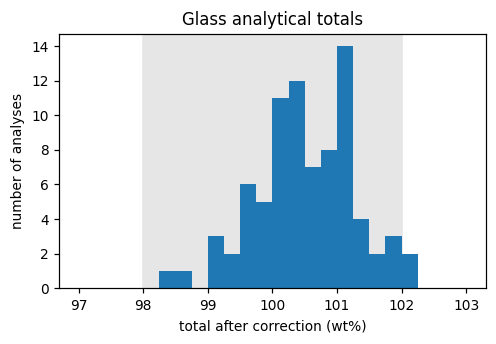

In [8]:
smp = corr[~is_std].copy()
smp["total_flag"] = np.select([smp.Total < 98, smp.Total > 102], ["< 98", "> 102"], "")
print(smp.total_flag.replace("", "98-102").value_counts().to_string())
print(smp.loc[smp.total_flag != "", ["No.", "Comment", "Total"]].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 3))
ax.hist(smp.Total, bins=np.arange(97, 103.01, 0.25))
ax.axvspan(98, 102, color="0.9", zorder=0)
ax.set(xlabel="total after correction (wt%)", ylabel="number of analyses", title="Glass analytical totals")
fig.savefig(FIG / "totals.png"); plt.show()

Visual check of the sample analyses, oxide by oxide against analysis number (values below are raw). Two analyses are obviously not glass of their sample and are excluded from the figures and averages:
- **No. 49** (`UnknA-C22-PS1-L3_5`): MgO 13.8, CaO 23.3, Al₂O₃ 6.4, Na₂O 0.4 wt%, against 5.4 to 5.8, 11.0 to 12.7, 15.2 to 15.7 and 3.0 to 4.0 in the other eight spots.
- **No. 65** (`UnknA-BatokeCS1-3_4`): Na₂O 8.6 and K₂O 1.3 wt%, against 4.9 to 6.9 and 2.0 to 2.7, with the highest total of the session.

Two analyses are wrong in one oxide only; that oxide is excluded, the rest of the analysis is kept:
- **No. 32** (`UnknA-C21_6`): SO₃ 2.2 wt% against 0.08 to 0.13 in the other eight spots.
- **No. 70** (`UnknA-BatokeCS1-3_9`): Cl 0.70 wt% against 0.02 to 0.22.

Kept but noted: in `1982-CS2-L3A` spots 7 to 9 (No. 15 to 17) have Na₂O of 4.1 to 4.8 wt% against 2.4 to 2.9 in spots 1 to 6, and `UnknA-BatokeCS1-3` is heterogeneous in several oxides. Neither is obviously wrong; both show up as large 2SD.

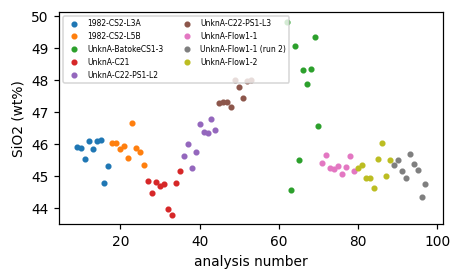

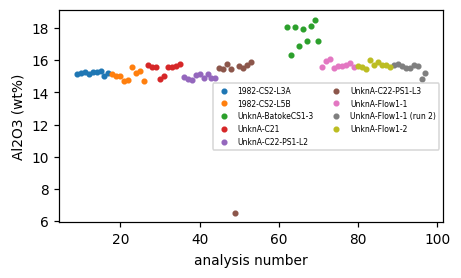

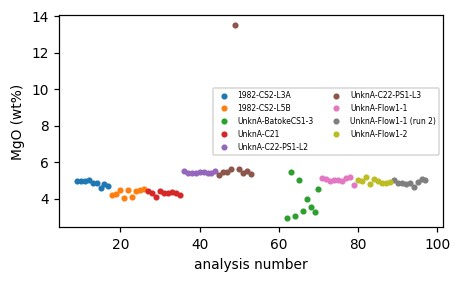

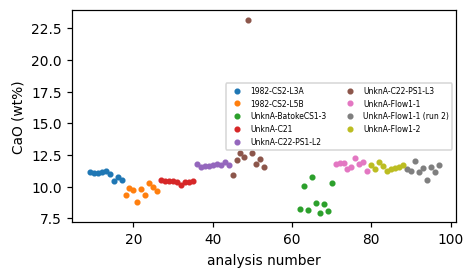

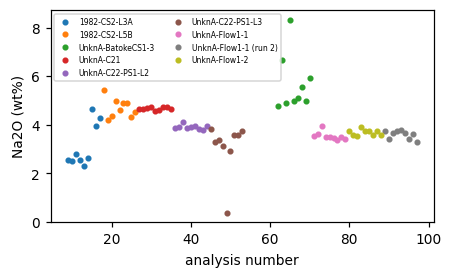

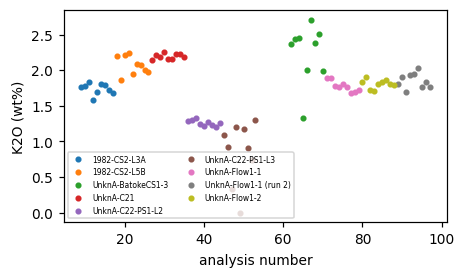

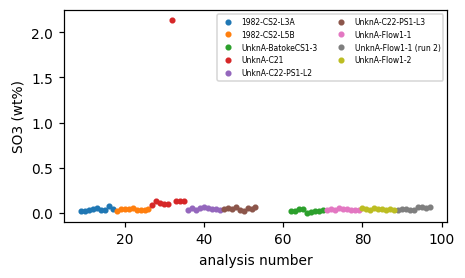

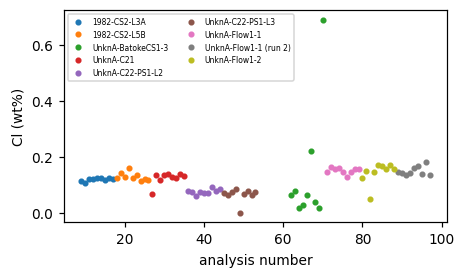

In [9]:
for el in ["SiO2", "Al2O3", "MgO", "CaO", "Na2O", "K2O", "SO3", "Cl"]:
    fig, ax = plt.subplots(figsize=(4.5, 2.5))
    for i, (s, d) in enumerate(smp.groupby("Sample")):
        ax.plot(d["No."], d[el], "o", ms=3, color=f"C{i % 10}", label=s)
    ax.set(xlabel="analysis number", ylabel=f"{el} (wt%)"); ax.legend(fontsize=5, ncol=2)
    plt.show()

BAD = {49: "not glass (MgO 13.8, CaO 23.3 wt%)", 65: "Na2O 8.6 wt%, total 102.5 wt%"}       # whole analysis
BAD_EL = {(32, "SO3"): "SO3 2.2 wt%, other spots 0.08 to 0.13", (70, "Cl"): "Cl 0.70 wt%, other spots 0.02 to 0.22"}   # one oxide
smp["exclude"] = smp["No."].isin(BAD)
smp["note"] = smp["No."].map(BAD).fillna("")
for (no, el), why in BAD_EL.items():
    smp.loc[smp["No."].eq(no), "note"] = f"{el} excluded: {why}"          # oxide-level exclusion, applied in step 10

In [10]:
a = smp.loc[smp.Sample.str.startswith("UnknA-Flow1-1"), :].groupby("Sample")[OX]
print("Flow1-1, run 1 vs run 2 (mean ± 2SD):")
print(pd.concat([a.mean().T, 2 * a.std().T], axis=1, keys=["mean", "2SD"]).round(2).to_string())

dl = read_dl(DATA / "bgls_20122016_all.txt")[OX]
below = smp[OX].lt(dl.loc[smp["No."]].values)
smp[[f"{el}_bdl" for el in OX]] = below.values
dlt = pd.DataFrame({"DL_median": dl.loc[smp["No."]].median(), "sample_median": smp[OX].median(),
                    "n_below_DL": below.sum(), "n": len(smp)})
print("\ndetection limits, wt% oxide:"); print(dlt.round(4).to_string())

Flow1-1, run 1 vs run 2 (mean ± 2SD):
                mean                                 2SD                      
Sample UnknA-Flow1-1 UnknA-Flow1-1 (run 2) UnknA-Flow1-1 UnknA-Flow1-1 (run 2)
SiO2           45.34                 45.15          0.40                  0.81
TiO2            3.33                  3.29          0.09                  0.07
Al2O3          15.74                 15.51          0.37                  0.62
FeO            13.13                 13.28          0.82                  1.04
MnO             0.22                  0.25          0.07                  0.11
MgO             5.03                  4.91          0.27                  0.26
CaO            11.75                 11.35          0.60                  0.83
Na2O            3.54                  3.60          0.35                  0.34
K2O             1.78                  1.85          0.15                  0.21
P2O5            0.71                  0.71          0.10                  0.10
SO3           

## Step 10. Final data

Corrected sample analyses with their flags, and sample averages (n, mean, 2SD) of the analyses not excluded (n counts analyses; for C21 SO₃ and BatokeCS1-3 Cl one fewer value enters the mean). Ready for the figures and the paper table.

In [11]:
fin = smp[~smp.exclude].copy()
for (no, el) in BAD_EL:
    fin.loc[fin["No."].eq(no), el] = np.nan
samples = mean_2sd(fin, "Sample", OX + ["Total"])
with pd.ExcelWriter(OUT / "glass_final.xlsx") as xw:
    smp.to_excel(xw, sheet_name="samples corrected", index=False)
    samples.to_excel(xw, sheet_name="sample means")
    qc.to_excel(xw, sheet_name="standard QC")
    hold.to_excel(xw, sheet_name="hold-out accuracy")
    ind.to_excel(xw, sheet_name="independent accuracy")
    dlt.to_excel(xw, sheet_name="detection limits")
    sc.reset_index().to_excel(xw, sheet_name="standards corrected", index=False)
    ref.to_excel(xw, sheet_name="references")
print(len(fin), "analyses,", len(samples), "sample sets")
print(samples.round(2).to_string())

79 analyses, 9 sample sets
                       n   SiO2  SiO2_2SD  TiO2  TiO2_2SD  Al2O3  Al2O3_2SD    FeO  FeO_2SD   MnO  MnO_2SD   MgO  MgO_2SD    CaO  CaO_2SD  Na2O  Na2O_2SD   K2O  K2O_2SD  P2O5  P2O5_2SD   SO3  SO3_2SD    Cl  Cl_2SD     F  F_2SD   Total  Total_2SD
Sample                                                                                                                                                                                                                                               
1982-CS2-L3A           9  45.74      0.90  3.91      0.10  15.22       0.18  13.33     0.83  0.22     0.07  4.86     0.30  10.94     0.59  3.14      1.79  1.74     0.15  0.66      0.11  0.04     0.04  0.12    0.01  0.14   0.06  100.06       0.60
1982-CS2-L5B           9  45.90      0.73  3.80      0.14  15.06       0.60  13.69     1.69  0.26     0.07  4.34     0.37   9.65     0.89  4.70      0.79  2.07     0.26  0.73      0.05  0.04     0.02  0.13    0.03  0.20   0.08  100.57 